In [ ]:
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from sklearn.ensemble import RandomForestRegressor
from sklearn.decomposition import PCA
import joblib
import warnings

warnings.filterwarnings("ignore", category=RuntimeWarning)

In [ ]:
PATH = r"E:\satdata\Custom\yucatan_sst_chlor_cdomslope_ssl_bathy_2010-2019_v3.pkl"
MODEL_PATH = r"F:\Programming\GitHub\nasa-murep\yucatan\experiments\isolation_forest\iforest_pipeline1.joblib"

features = ["chlor", "ssl", "sst", "time_sin", "time_cos"]

In [ ]:
with open(PATH, "rb") as f:
    blob = pickle.load(f)

df = blob["data"]
metadata = blob["metadata"]
df = df[(df.index.year >= 2017) & (df.index.year <= 2019)]

grid_shape = np.asarray(df["sst"].iloc[0]).shape

def shape_ok(a):
    return a is not None and np.asarray(a).shape == grid_shape

keep = df["sst"].apply(shape_ok) & df["chlorophyll"].apply(shape_ok) & df["ssl"].apply(shape_ok)
df = df[keep]

sst_stack = np.stack(df["sst"].to_numpy()).astype(float)
chlor_stack = np.stack(df["chlorophyll"].to_numpy()).astype(float)
ssl_stack = np.stack(df["ssl"].to_numpy()).astype(float)

In [ ]:
pipeline = joblib.load(MODEL_PATH)
preprocess = pipeline.named_steps["preprocess"]
iforest = pipeline.named_steps["iforest"]
print(f"Loaded pipeline from {MODEL_PATH}")

Loaded pipeline from F:\Programming\GitHub\nasa-murep-local\cdom_sst\experiments\clustering\isolation_forest\iforest_pipeline1.joblib


In [ ]:
start_date = pd.Timestamp("2018-07-01")
end_date = pd.Timestamp("2018-07-31")

window_mask = (df.index >= start_date) & (df.index <= end_date)
n_days = int(window_mask.sum())
if n_days == 0:
    raise ValueError(f"No valid days found between {start_date.date()} and {end_date.date()}")

with np.errstate(invalid="ignore"):  # average over available days
    mean_sst = np.nanmean(sst_stack[window_mask], axis=0)
    mean_chlor = np.nanmean(chlor_stack[window_mask], axis=0)
    mean_ssl = np.nanmean(ssl_stack[window_mask], axis=0)

valid_2d = ~np.isnan(mean_sst) & ~np.isnan(mean_chlor) & ~np.isnan(mean_ssl) & (mean_chlor > 0)
row_w, col_w = np.where(valid_2d)

# use middle of window for DOY time encoding
center_date = start_date + (end_date - start_date) / 2
center_doy = center_date.timetuple().tm_yday

X_window = pd.DataFrame({
    "sst": mean_sst[valid_2d],
    "chlor": mean_chlor[valid_2d],
    "ssl": mean_ssl[valid_2d],
    "time_sin": np.sin(2 * np.pi * center_doy / 365.25),
    "time_cos": np.cos(2 * np.pi * center_doy / 365.25),
})[features]

X_window_transformed = preprocess.transform(X_window)
window_anomaly_score = -iforest.decision_function(X_window_transformed)
window_raw_anomaly = iforest.predict(X_window_transformed) == -1

sst_z_w = X_window_transformed["normal__sst"].to_numpy()
ssl_z_w = X_window_transformed["skewed__ssl"].to_numpy()

window_is_upwelling = (window_raw_anomaly &
                      (sst_z_w < 0) &           # anomalously cold SST
                      (ssl_z_w < 0))            # anomalously low SSL

In [ ]:
start_date = pd.Timestamp("2018-12-01")
end_date = pd.Timestamp("2018-12-31")

In [ ]:
window_mask = (df.index >= start_date) & (df.index <= end_date)
n_days = int(window_mask.sum())
if n_days == 0:
    raise ValueError(f"No valid days found between {start_date.date()} and {end_date.date()}")

with np.errstate(invalid="ignore"):  # average over available days
    mean_sst = np.nanmean(sst_stack[window_mask], axis=0)
    mean_chlor = np.nanmean(chlor_stack[window_mask], axis=0)
    mean_ssl = np.nanmean(ssl_stack[window_mask], axis=0)

valid_2d = ~np.isnan(mean_sst) & ~np.isnan(mean_chlor) & ~np.isnan(mean_ssl) & (mean_chlor > 0)
row_w, col_w = np.where(valid_2d)

# use middle of window for DOY time encoding
center_date = start_date + (end_date - start_date) / 2
center_doy = center_date.timetuple().tm_yday

X_window = pd.DataFrame({
    "sst": mean_sst[valid_2d],
    "chlor": mean_chlor[valid_2d],
    "ssl": mean_ssl[valid_2d],
    "time_sin": np.sin(2 * np.pi * center_doy / 365.25),
    "time_cos": np.cos(2 * np.pi * center_doy / 365.25),
})[features]

X_window_transformed = preprocess.transform(X_window)
window_anomaly_score = -iforest.decision_function(X_window_transformed)
window_raw_anomaly = window_anomaly_score >= np.percentile(window_anomaly_score, 95)

sst_z_w = X_window_transformed["normal__sst"].to_numpy()
ssl_z_w = X_window_transformed["skewed__ssl"].to_numpy()

window_is_upwelling = (window_raw_anomaly &
                      (sst_z_w < 0) &           # anomalously cold SST
                      (ssl_z_w < 0))            # anomalously low SSL

In [ ]:
# use RF to predict the anomaly score. RF's feature weights
# act as a proxy for what drove isolation forest's decisions
surrogate = RandomForestRegressor(n_estimators=100, max_depth=5, random_state=42, n_jobs=-1)
surrogate.fit(X_window_transformed, window_anomaly_score)

importances = surrogate.feature_importances_
feature_names = X_window_transformed.columns
importance_dict = {name: weight * 100 for name, weight in zip(feature_names, importances)}

print("\n--- Feature Importance (% of variance in anomaly score explained) ---")
for feat, imp in sorted(importance_dict.items(), key=lambda item: item[1], reverse=True):
    print(f"{feat:>15}: {imp:>5.1f}%")


--- Feature Importance (% of variance in anomaly score explained) ---
    skewed__ssl:  52.6%
  skewed__chlor:  46.6%
    normal__sst:   0.7%
normal__time_sin:   0.0%
normal__time_cos:   0.0%


In [ ]:
non_upwelling_mask = ~window_is_upwelling

print(f"\n--- Window: {start_date.date()} to {end_date.date()} ({n_days} days averaged) ---")
print(f"Total Valid Pixels: {len(X_window):,}")
print(f"Raw Anomalies: {window_raw_anomaly.sum():,}")
print(f"Upwelling Anomalies: {window_is_upwelling.sum():,}\n")

print("Mean States (Upwelling Anomaly vs Non-Anomaly):")
print(f"SST   | Upwelling: {X_window['sst'][window_is_upwelling].mean():.2f} \u00b0C  | Non-Anomaly: {X_window['sst'][non_upwelling_mask].mean():.2f} \u00b0C")
print(f"Chlor | Upwelling: {X_window['chlor'][window_is_upwelling].mean():.3f} mg/m3 | Non-Anomaly: {X_window['chlor'][non_upwelling_mask].mean():.3f} mg/m3")
print(f"SSL   | Upwelling: {X_window['ssl'][window_is_upwelling].mean():.3f} m  | Non-Anomaly: {X_window['ssl'][non_upwelling_mask].mean():.3f} m\n")


--- Window: 2018-12-01 to 2018-12-31 (31 days averaged) ---
Total Valid Pixels: 45,061
Raw Anomalies: 2,254
Upwelling Anomalies: 508

Mean States (Upwelling Anomaly vs Non-Anomaly):
SST   | Upwelling: 24.11 °C  | Non-Anomaly: 26.03 °C
Chlor | Upwelling: 7.603 mg/m3 | Non-Anomaly: 0.790 mg/m3
SSL   | Upwelling: 0.312 m  | Non-Anomaly: 0.411 m



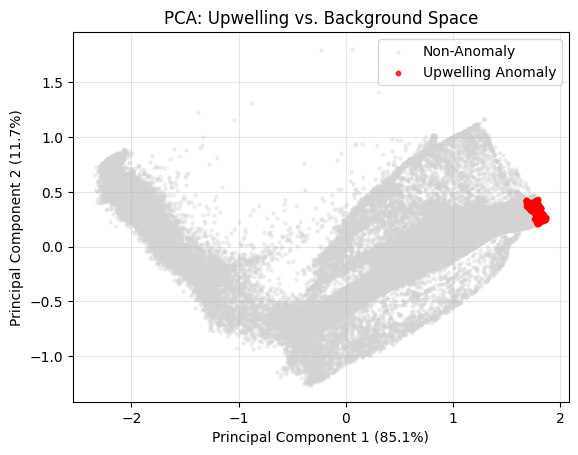

In [ ]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_window_transformed)
var_explained = pca.explained_variance_ratio_ * 100

plt.scatter(X_pca[non_upwelling_mask, 0], X_pca[non_upwelling_mask, 1],
            c='lightgray', alpha=0.3, s=5, label='Non-Anomaly')
plt.scatter(X_pca[window_is_upwelling, 0], X_pca[window_is_upwelling, 1],
            c='red', alpha=0.8, s=10, label='Upwelling Anomaly')
plt.title("PCA: Upwelling vs. Background Space")
plt.xlabel(f"Principal Component 1 ({var_explained[0]:.1f}%)")
plt.ylabel(f"Principal Component 2 ({var_explained[1]:.1f}%)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [ ]:
X_window_transformed

,skewed__chlor,skewed__ssl,normal__sst,normal__time_sin,normal__time_cos
0,0.788070,0.231039,-0.345311,-0.361083,1.266727
1,0.731183,0.224432,-0.350040,-0.361083,1.266727
2,0.681316,0.217859,-0.363935,-0.361083,1.266727
3,0.712307,0.211323,-0.374356,-0.361083,1.266727
4,0.708228,0.204826,-0.381963,-0.361083,1.266727
...,...,...,...,...,...
45056,-0.678747,1.955865,0.298122,-0.361083,1.266727
45057,-0.605571,1.968763,0.283897,-0.361083,1.266727
45058,-0.367083,1.980757,0.275652,-0.361083,1.266727
45059,-0.610086,1.991817,0.281004,-0.361083,1.266727


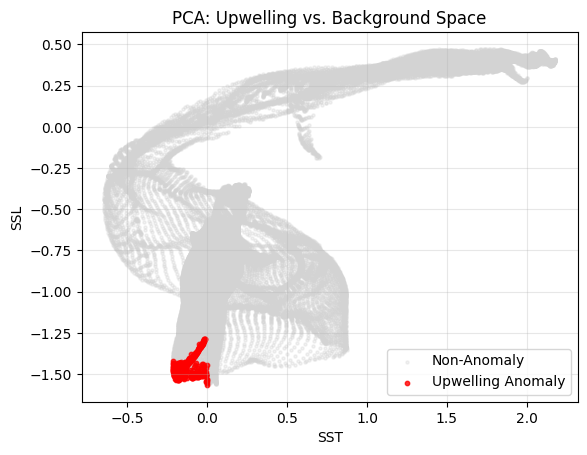

In [ ]:
nu_ssl = X_window_transformed["skewed__ssl"][non_upwelling_mask]
u_ssl  = X_window_transformed["skewed__ssl"][~non_upwelling_mask]
nu_sst = X_window_transformed["normal__sst"][non_upwelling_mask]
u_sst  = X_window_transformed["normal__sst"][~non_upwelling_mask]

plt.scatter(nu_ssl, nu_sst,
            c='lightgray', alpha=0.3, s=5, label='Non-Anomaly')
plt.scatter(u_ssl, u_sst,
            c='red', alpha=0.8, s=10, label='Upwelling Anomaly')
plt.title("PCA: Upwelling vs. Background Space")

plt.xlabel(f"SST")
plt.ylabel(f"SSL")

plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

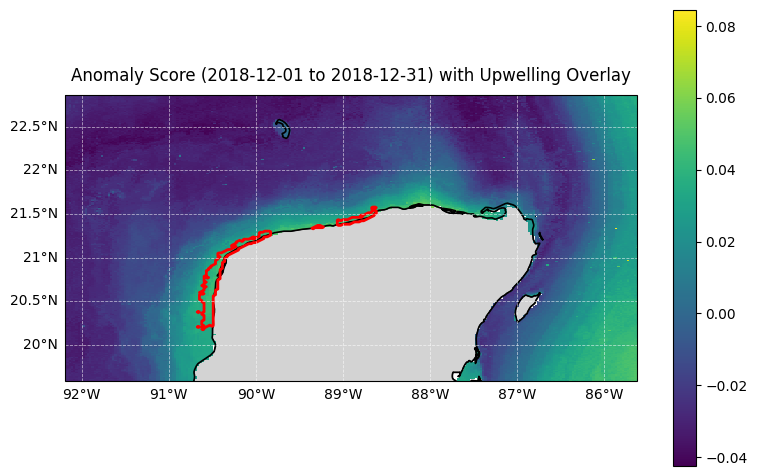

In [ ]:
score_map = np.full(grid_shape, np.nan)
score_map[row_w, col_w] = window_anomaly_score

binary_mask = np.zeros(grid_shape, dtype=float)
binary_mask[row_w[window_is_upwelling], col_w[window_is_upwelling]] = 1.0

lon_centers = np.array(metadata["lon_centers"])
lat_centers = np.array(metadata["lat_centers"])
lon_grid_2d, lat_grid_2d = np.meshgrid(lon_centers, lat_centers)

fig, ax = plt.subplots(
    figsize=(8, 6), subplot_kw={"projection": ccrs.PlateCarree()}
)

ax.set_extent(
    [lon_centers.min(), lon_centers.max(), lat_centers.min(), lat_centers.max()],
    crs=ccrs.PlateCarree(),
)

mesh = ax.pcolormesh(
    lon_grid_2d, lat_grid_2d, score_map,
    cmap="viridis", transform=ccrs.PlateCarree(), shading="auto"
)

ax.contour(
    lon_grid_2d, lat_grid_2d, binary_mask,
    levels=[0.5], colors="red", linewidths=2.0, transform=ccrs.PlateCarree()
)

ax.add_feature(cfeature.LAND, facecolor="lightgray", edgecolor="black", linewidth=0.8)
ax.add_feature(cfeature.COASTLINE, linewidth=1.2)
gl = ax.gridlines(draw_labels=True, linewidth=0.6, color="white", alpha=0.6, linestyle="--")
gl.top_labels = False
gl.right_labels = False

ax.set_title(f"Anomaly Score ({start_date.date()} to {end_date.date()}) with Upwelling Overlay", pad=10)
fig.colorbar(mesh, ax=ax, orientation="vertical", shrink=0.8, pad=0.05)

plt.tight_layout()
plt.show()